# Voiceprint breakdown

How the stage-1 Conformers' embeddings (voiceprints) change between block spans where verification still works and where it breaks down. The breakdown point is between SS (64 ms) and BS8 (134 ms), so BS2 and BS4 (74 and 94 ms) are added to place it. The probes are meant to tell two explanations apart:

- **(a) Short-range temporal structure:** the model needs order within ~50–130 ms. Shuffling then moves each speaker's embedding in its own direction, and speakers stay spread out.
- **(b) Out-of-distribution input:** every block boundary is a spectral discontinuity. Embeddings then shift along one shared "shuffled" direction and collapse toward each other.

The figures:

1. **Drift and EER** over block span. Drift is the mean 1 − cos(e_OS, e_S) per utterance, as in `temporal-probes.ipynb`.
2. **Score distributions:** target and non-target cosine scores per strategy. If non-target scores rise, embeddings are collapsing (b). If target scores fall, they are scattering (a).
3. **Shift structure:** the mean pairwise cosine of the shifts Δ = e_S − e_OS, within and across speakers, plus the participation ratio (effective dimensionality) of the embeddings. A high across-speaker alignment or a falling participation ratio points to (b).
4. **PCA picture:** a 2D PCA fit on OS embeddings only. Shuffled embeddings are projected into it, with a line from each utterance's OS point.

All scores are all-pairs within a speaker-balanced subset of VoxCeleb1-O, not the official trial list. EERs are therefore comparable across strategies and models, but not to the logged `test/EER`. Model C has no shift (Δ = 0), so its alignment is undefined and is left out.

Needs the best checkpoints kept by the stage-1 runs (`training.keep_checkpoints`).

In [1]:
!module load uv && uv pip compile ../pyproject.toml -o ../requirements.txt
!source $HOME/dev/cluster_user/py_mgmt_3_venv_gpu_detect/gpu-detect.sh && pip install -r ../requirements.txt --index-url "$PYTORCH_INDEX_URL" --extra-index-url https://pypi.org/simple

Resolved 104 packages in 39ms                                        
# This file was autogenerated by uv via the following command:
#    uv pip compile ../pyproject.toml -o ../requirements.txt
annotated-doc==0.0.5
    # via typer
annotated-types==0.8.0
    # via pydantic
anyio==4.15.1
    # via
    #   cwevals
    #   httpx
    #   httpx2
certifi==2026.10.19
    # via
    #   httpcore
    #   httpx
    #   requests
cffi==2.1.1
    # via soundfile
charset-normalizer==3.5.2
    # via requests
click==8.5.0
    # via
    #   huggingface-hub
    #   wandb
cloudpickle==3.1.2
    # via joblib
contourpy==1.4.0
    # via matplotlib
cuda-bindings==13.4.4
    # via torch
cuda-pathfinder==1.8.3
    # via cuda-bindings
cuda-toolkit==13.0.3.0
    # via torch
cwevals==0.0.1b1
    # via wandb
cycler==0.12.1
    # via matplotlib
distro==1.9.0
    # via cwevals
filelock==4.2.4
    # via
    #   huggingface-hub
    #   torch
fonttools==4.67.0
    # via matplotlib
fsspec==2026.9.0
    # via
    #   huggi

In [ ]:
!source ../slurm/stage-voxceleb.submit

In [2]:
import os
import sys
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

ROOT = Path.cwd().parent  # notebook runs from doc/
sys.path.insert(0, str(ROOT))

from src.config import ExperimentConfig
from src.data.voxceleb import VoxCelebCorpus
from src.evaluation.verification import build_verification_pairs, equal_error_rate
from src.experiment import _checkpoint_path, _lazy_trial_utterances
from src.models.registry import build_model
from src.training.trainer import best_checkpoint_path, extract_embeddings_by_strategy

# VoxCeleb as staged by slurm/stage-voxceleb.submit in this job (e.g. from temporal-probes.ipynb)
stage_dir = f"/scratch/{os.environ['SLURM_JOB_ID']}"
os.environ["VOXCELEB_ROOT"] = f"{stage_dir}/voxceleb1"
os.environ["VOXCELEB2_ROOT"] = f"{stage_dir}/voxceleb2"

In [3]:
models = {  # label -> (config the checkpoint was trained with, train strategy)
    "A (OS)": ("configs/conformer-voxceleb-stage1.yaml", "OS"),
    "B (RANDBS)": ("configs/conformer-voxceleb-stage1.yaml", "RANDBS"),
    "C (invariant)": ("configs/conformer-voxceleb-stage1-invariant.yaml", "OS"),
}
block_sizes = [1, 2, 4, 8, 16, 32, 64]  # SS, BS2, ..., BS64
pca_strategies = ["BS8", "BS4", "SS"]   # columns of the PCA figure
run_idx = 0
utterances_per_speaker = 25  # VoxCeleb1-O has 40 speakers
pca_speakers = 8
max_scores = 5000            # target / non-target scores drawn per violin
device = "cuda" if torch.cuda.is_available() else "cpu"

model_colors = dict(zip(models, ["#2a78d6", "#eb6834", "#1baf7a"]))
speaker_colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

In [4]:
def load(config_path, train_strategy):
    config = ExperimentConfig.from_yaml(ROOT / config_path)
    config.training.checkpoint_dir = str(ROOT / config.training.checkpoint_dir)
    model = build_model(config)
    checkpoint = torch.load(best_checkpoint_path(_checkpoint_path(config, train_strategy, run_idx)), map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    return config, model.to(device).eval()


loaded = {label: load(*entry) for label, entry in models.items()}
config = next(iter(loaded.values()))[0]
transformation = config.transformation
corpus = VoxCelebCorpus(config)
segment_length = config.data.segment_length(transformation)

# Speaker-balanced subset: utterances_per_speaker random utterances of each speaker.
by_speaker = defaultdict(list)
for entry in _lazy_trial_utterances(corpus, corpus.dev_trial_pairs, transformation):
    by_speaker[entry[1].split("/")[0]].append(entry)
rng = np.random.default_rng(0)
utterances = [
    entries[i]
    for _, entries in sorted(by_speaker.items())
    for i in sorted(rng.choice(len(entries), min(utterances_per_speaker, len(entries)), replace=False))
]

==> VoxCeleb1: 153516 utterances (cached index /scratch/155204/voxceleb1/.sst-wav-index.tsv)
==> VoxCeleb2: 1092009 utterances (cached index /scratch/155204/voxceleb2/.sst-wav-index.tsv)


In [6]:
strategies = ["SS" if b == 1 else f"BS{b}" for b in block_sizes] + ["OS"]
frame_step_ms, frame_length_ms = transformation.frame_step_s * 1000, transformation.frame_length_s * 1000
block_ms = [(b - 1) * frame_step_ms + frame_length_ms for b in [*block_sizes, segment_length]]  # OS spans the whole segment


def normalized(x):
    return x / np.linalg.norm(x, axis=-1, keepdims=True)


# Same seed for every strategy, as in permutation_sensitivity: all strategies
# embed the same hop windows and differ only in frame order.
embeddings = {}
for label, (_, model) in loaded.items():
    rngs = {strategy: np.random.default_rng(0) for strategy in strategies}
    by_strategy = extract_embeddings_by_strategy(model, utterances, segment_length, rngs, device, log_every=250)
    embeddings[label] = {strategy: normalized(e) for strategy, (e, _) in by_strategy.items()}
    utterance_ids = by_strategy["OS"][1]
speakers = np.array([utterance_id.split("/")[0] for utterance_id in utterance_ids])
print(f"{len(speakers)} utterances of {len(set(speakers))} speakers")

==> Embedded 1000/1000 utterances (64s)
==> Embedded 1000/1000 utterances (13s)
==> Embedded 1000/1000 utterances (86s)
1000 utterances of 40 speakers


## 1. Drift and EER

Both over the signal one shuffled block spans. OS is the rightmost point, a block spanning the whole segment.

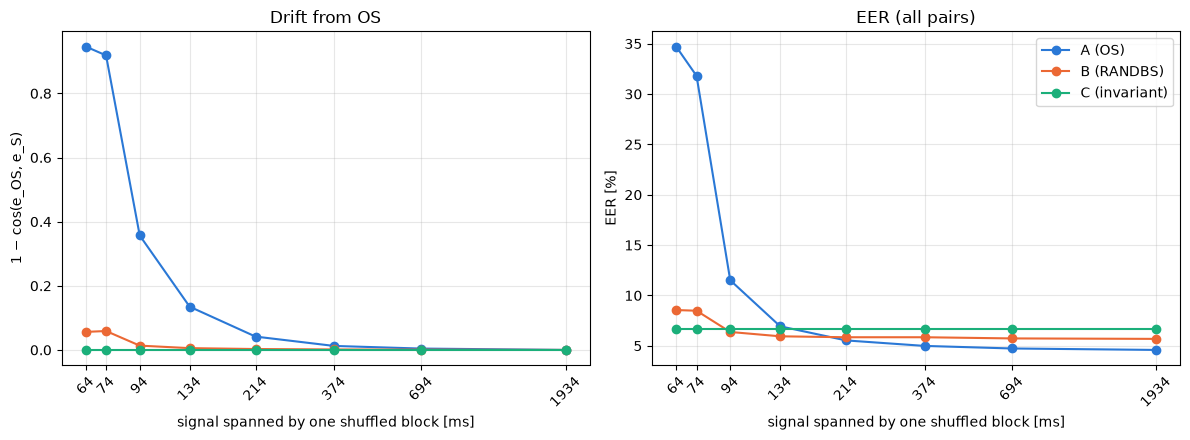

In [7]:
fig, (ax_drift, ax_eer) = plt.subplots(1, 2, figsize=(12, 4.5))
for label, by_strategy in embeddings.items():
    drift = [float(np.mean(1 - np.sum(by_strategy["OS"] * by_strategy[s], axis=-1))) for s in strategies]
    eer = [100 * equal_error_rate(by_strategy[s], speakers) for s in strategies]
    ax_drift.plot(block_ms, drift, "o-", color=model_colors[label], label=label)
    ax_eer.plot(block_ms, eer, "o-", color=model_colors[label], label=label)
for ax, title, ylabel in ((ax_drift, "Drift from OS", "1 − cos(e_OS, e_S)"), (ax_eer, "EER (all pairs)", "EER [%]")):
    ax.set(title=title, xscale="log", xlabel="signal spanned by one shuffled block [ms]", ylabel=ylabel)
    ax.set_xticks(block_ms, [f"{ms:.0f}" for ms in block_ms], rotation=45)
    ax.minorticks_off()
    ax.grid(alpha=0.3)
ax_eer.legend()
plt.tight_layout()
plt.show()

## 2. Score distributions

Target (same speaker) scores on the left half of each violin, non-target on the right. The EER sits where the two overlap.

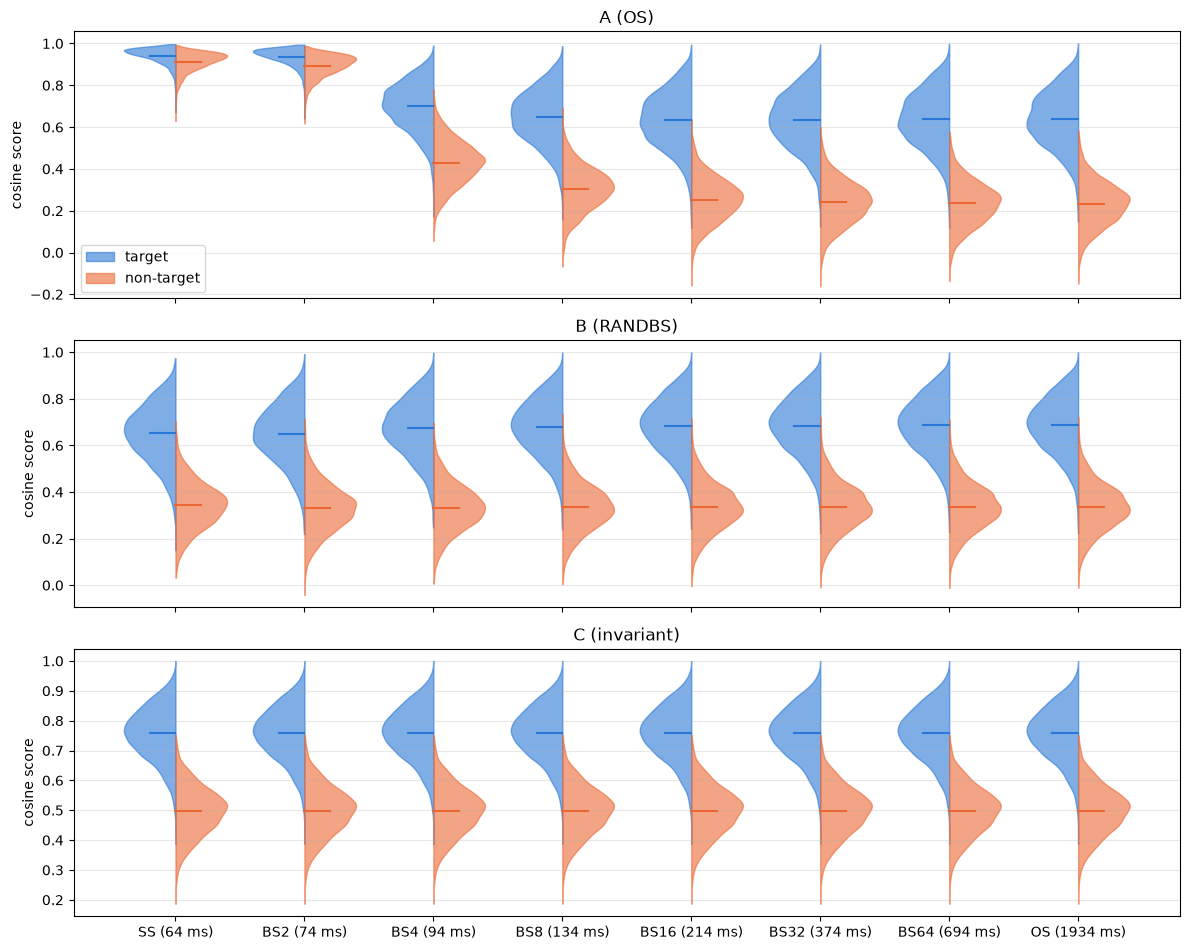

In [8]:
idx1, idx2, is_target = build_verification_pairs(speakers)
rng = np.random.default_rng(0)
drawn = np.concatenate([
    rng.choice(np.flatnonzero(is_target == t), min(max_scores, int(np.sum(is_target == t))), replace=False)
    for t in (1, 0)
])
idx1, idx2, is_target = idx1[drawn], idx2[drawn], is_target[drawn]
names = [f"{s} ({ms:.0f} ms)" for s, ms in zip(strategies, block_ms)]

fig, axes = plt.subplots(len(embeddings), 1, figsize=(12, 3.2 * len(embeddings)), sharex=True, squeeze=False)
positions = np.arange(len(strategies))
for ax, (label, by_strategy) in zip(axes[:, 0], embeddings.items()):
    for t, side, name, color in ((1, "low", "target", "#2a78d6"), (0, "high", "non-target", "#eb6834")):
        mask = is_target == t
        scores = [np.sum(by_strategy[s][idx1[mask]] * by_strategy[s][idx2[mask]], axis=-1) for s in strategies]
        parts = ax.violinplot(scores, positions, side=side, showmeans=True, showextrema=False, widths=0.8)
        for body in parts["bodies"]:
            body.set(facecolor=color, edgecolor=color, alpha=0.6)
        parts["cmeans"].set_color(color)
        ax.fill([], [], color=color, alpha=0.6, label=name)  # legend entry
    ax.set(title=label, ylabel="cosine score")
    ax.grid(axis="y", alpha=0.3)
axes[0, 0].legend()
axes[-1, 0].set_xticks(positions, names)
plt.tight_layout()
plt.show()

## 3. Shift structure

**Alignment:** the mean pairwise cosine between unit shift vectors Δ/‖Δ‖, separately for utterance pairs of the same speaker (solid) and of different speakers (dashed). Near 0 across speakers means each utterance moves its own way. A high value across speakers means a shared direction: the model sees "shuffled" rather than a speaker.

**Participation ratio:** (Σλ)² / Σλ² over the eigenvalues λ of the embeddings' covariance, i.e. how many dimensions the embeddings effectively spread over. A drop means collapse.

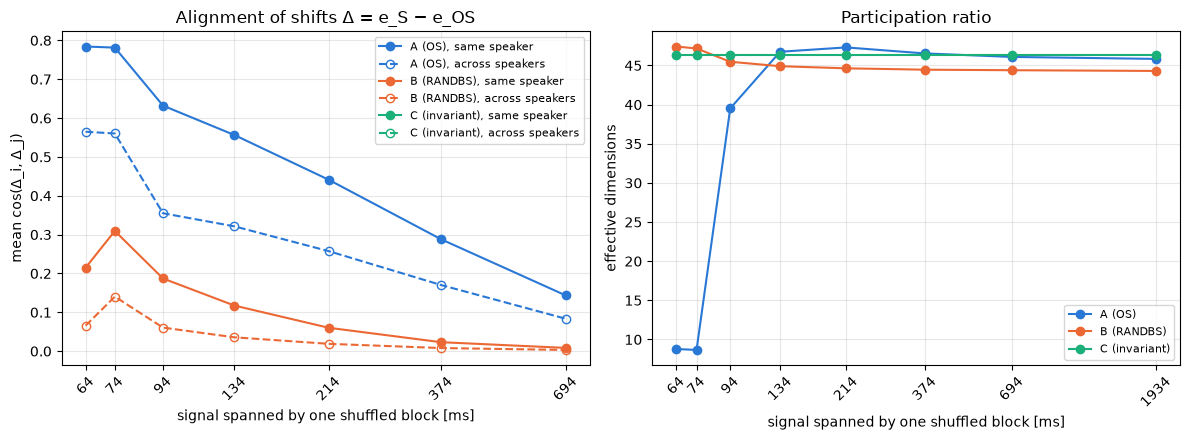

In [9]:
same_speaker = speakers[:, None] == speakers[None, :]
off_diagonal = ~np.eye(len(speakers), dtype=bool)


def alignment(delta):
    norms = np.linalg.norm(delta, axis=-1, keepdims=True)
    if np.median(norms) < 1e-6:  # no shift: model is invariant to this shuffle
        return np.nan, np.nan
    unit = delta / np.maximum(norms, 1e-12)
    gram = unit @ unit.T
    return float(gram[same_speaker & off_diagonal].mean()), float(gram[~same_speaker].mean())


def participation_ratio(x):
    eigenvalues = np.linalg.eigvalsh(np.cov(x, rowvar=False))
    return float(eigenvalues.sum() ** 2 / np.sum(eigenvalues ** 2))


shuffled = strategies[:-1]
fig, (ax_alignment, ax_ratio) = plt.subplots(1, 2, figsize=(12, 4.5))
for label, by_strategy in embeddings.items():
    within, across = zip(*(alignment(by_strategy[s] - by_strategy["OS"]) for s in shuffled))
    color = model_colors[label]
    ax_alignment.plot(block_ms[:-1], within, "o-", color=color, label=f"{label}, same speaker")
    ax_alignment.plot(block_ms[:-1], across, "o--", color=color, markerfacecolor="none", label=f"{label}, across speakers")
    ax_ratio.plot(block_ms, [participation_ratio(by_strategy[s]) for s in strategies], "o-", color=color, label=label)
ax_alignment.set(title="Alignment of shifts Δ = e_S − e_OS", ylabel="mean cos(Δ_i, Δ_j)")
ax_ratio.set(title="Participation ratio", ylabel="effective dimensions")
for ax, ticks in ((ax_alignment, block_ms[:-1]), (ax_ratio, block_ms)):
    ax.set(xscale="log", xlabel="signal spanned by one shuffled block [ms]")
    ax.set_xticks(ticks, [f"{ms:.0f}" for ms in ticks], rotation=45)
    ax.minorticks_off()
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. PCA picture

The first two principal components of `pca_speakers` speakers' OS embeddings, fit per model on OS only. Open circles are OS, filled ones the shuffled embedding of the same utterance, joined by a line. Under (b) the filled points slide together toward one region. Under (a) they leave their speaker's cluster in different directions.

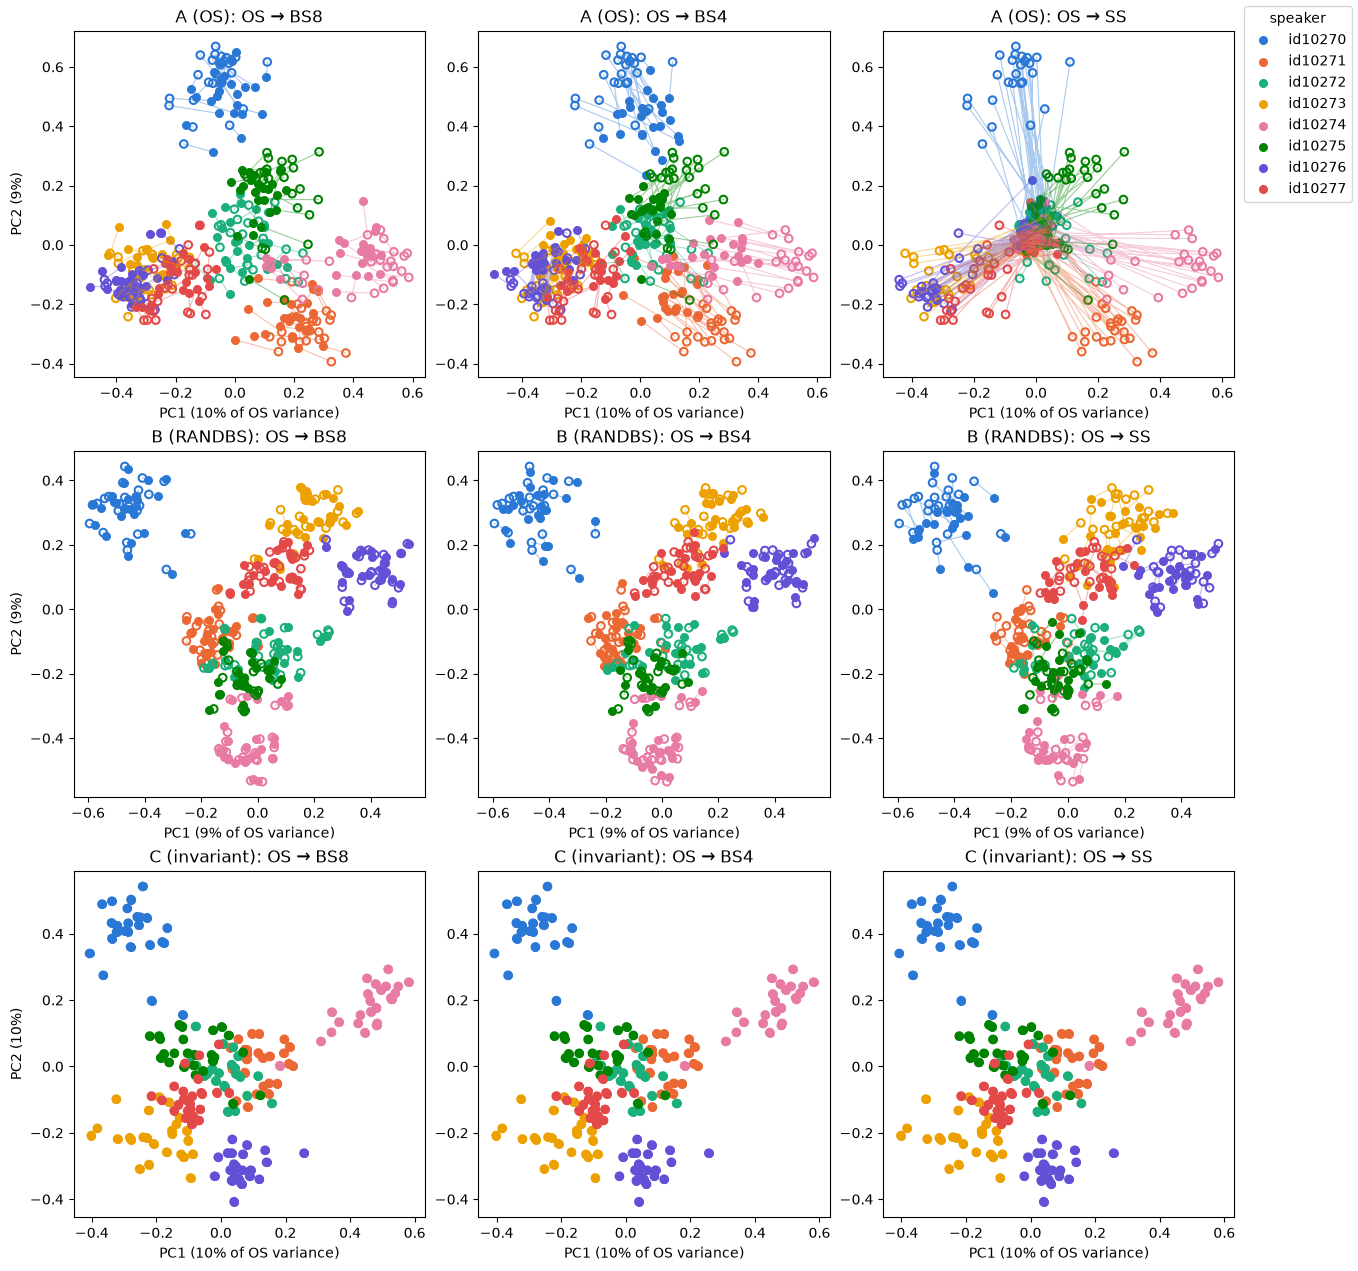

In [10]:
shown = sorted(set(speakers))[:pca_speakers]
fig, axes = plt.subplots(len(embeddings), len(pca_strategies), figsize=(4.5 * len(pca_strategies), 4.2 * len(embeddings)),
                         squeeze=False, layout="constrained")
for row, (label, by_strategy) in zip(axes, embeddings.items()):
    mask = np.isin(speakers, shown)
    os_points = by_strategy["OS"][mask]
    mean = os_points.mean(axis=0)
    _, singular_values, components = np.linalg.svd(os_points - mean, full_matrices=False)
    explained = singular_values[:2] ** 2 / np.sum(singular_values ** 2)
    project = lambda x: (x - mean) @ components[:2].T
    for ax, strategy in zip(row, pca_strategies):
        origin, moved = project(os_points), project(by_strategy[strategy][mask])
        for speaker, color in zip(shown, speaker_colors):
            mine = speakers[mask] == speaker
            segments = np.stack([origin[mine], moved[mine], np.full_like(origin[mine], np.nan)], axis=1).reshape(-1, 2)
            ax.plot(segments[:, 0], segments[:, 1], color=color, linewidth=0.8, alpha=0.4)
            ax.scatter(origin[mine, 0], origin[mine, 1], s=30, facecolors="none", edgecolors=color, linewidths=1.5)
            ax.scatter(moved[mine, 0], moved[mine, 1], s=30, color=color, label=speaker)
        ax.set(title=f"{label}: OS → {strategy}", xlabel=f"PC1 ({explained[0]:.0%} of OS variance)")
    row[0].set_ylabel(f"PC2 ({explained[1]:.0%})")
fig.legend(*axes[0, 0].get_legend_handles_labels(), title="speaker", loc="outside right upper")
plt.show()